# 04 · MPC — 계획하고, 한 발만 내딛고, 다시 계획

> 짧은 미래를 최적화해서 계획을 세우되 첫 입력만 실행하고, 다음 순간 실제 상태를 다시 보고 계획을 새로 세운다. 이 반복이 MPC다.

**지금 위치**

01 상태·입력·모델 → 02 비용 → 03 최적화 → **04 MPC** → 05~07 MPPI → 08~09 로봇팔 → 10~13 프로젝트

**이 노트를 끝내면**
1. 계획을 끝까지 따르는 방식(개루프)이 왜 실패하는지 예를 들어 설명할 수 있다.
2. receding horizon 루프(`run_mpc`)를 직접 쓰고, 외란에서 회복하는 것을 확인할 수 있다.
3. horizon 길이와 warm start가 결과와 계산량에 주는 영향을 설명할 수 있다.
4. MPC에 "아주 빠른 최적화"가 필요한 이유를 말할 수 있다.

**필요한 것:** [01](01_state_input_model.ipynb)의 "모델은 근사다", [02](02_cost_function.ipynb)의 `cart_cost`, [03](03_optimization.ipynb)의 경사하강·L-BFGS-B · **예상 시간:** 40분

## 복습 퀴즈 (03)

<details><summary>1. 경사하강의 한 걸음 식은?</summary>

$U \leftarrow U - \alpha \nabla J(U)$. 기울기 반대 방향으로 학습률 $\alpha$만큼 이동한다.
</details>

<details><summary>2. 학습률이 너무 크면 어떻게 되나?</summary>

골짜기를 건너뛰며 비용이 오히려 커진다(발산).
</details>

<details><summary>3. 국소 최솟값이란?</summary>

주변에서는 가장 낮지만 전체에서 가장 낮지는 않은 곳. 경사하강은 출발점에 따라 여기에 갇힐 수 있다.
</details>

In [1]:
import time
import numpy as np
from scipy.optimize import minimize
from common import setup_plot
from course import cart_step, cart_rollout, cart_cost, DT   # 01, 02에서 만든 코드
plt = setup_plot()
x0 = np.array([0.0, 0.0])
GOAL = 1.0

## 0. 이 노트의 "실제 카트"

01의 실제 카트에는 마찰이 있었다. 이번에는 현실에 한 가지를 더 넣는다. **모터 힘에 한계**가 있어서 가속도를 ±0.3 m/s²보다 크게 낼 수 없다.

| | 모델 (계획할 때 쓰는 것) | 실제 카트 |
|---|---|---|
| 가속도 한계 ±0.3 | 안다 (최적화에서 범위 제한) | 있다 |
| 마찰 (속도 × 0.1만큼 감속) | **모른다** | 있다 |

계획기(planner)는 03의 "실전 도구" L-BFGS-B를 쓴다. 기울기를 따라 내려가는 원리는 경사하강과 같고, 입력 범위 $|u| \le 0.3$을 지켜 준다. 기울기는 03의 `grad_batch`로 계산한다.

In [2]:
U_MAX, FRICTION = 0.3, 0.1

def real_cart_step(x, u):
    # 실제 카트: 모터 한계로 잘린 가속도에서 마찰만큼 뺀다
    u_real = np.clip(u, -U_MAX, U_MAX) - FRICTION * x[..., 1]
    return cart_step(x, u_real)

def grad_batch(f, U, eps=1e-5):                    # 03에서 만든 것과 같다
    E = np.eye(U.shape[-1]) * eps
    return (f(U + E) - f(U - E)) / (2 * eps)

n_evals = []                                       # 최적화 한 번에 비용을 몇 번 계산했는지 기록
def plan(x, U_init, maxiter=200):
    # 지금 상태 x에서 시작하는 최적 입력열을 찾는다 (모델 = 마찰 없는 cart_rollout)
    J = lambda U: cart_cost(cart_rollout(x, U), U)
    res = minimize(J, U_init, jac=lambda U: grad_batch(J, U), method='L-BFGS-B',
                   bounds=[(-U_MAX, U_MAX)] * len(U_init), options={'maxiter': maxiter})
    n_evals.append(res.nfev)
    return res.x

## 1. 문제 — 계획을 끝까지 따르면

### 문제
지금까지 배운 것을 그대로 쓰면 이렇다. 4초짜리 계획(T=40)을 한 번 최적화하고, 그 입력열을 실제 카트에 처음부터 끝까지 넣는다.

**예측해 보기:** 모델은 마찰을 모른다. 실제 카트는 계획보다 앞에 설까, 뒤에 설까?

4초 뒤: 모델 예측 p=1.031 m, 실제 p=0.836 m


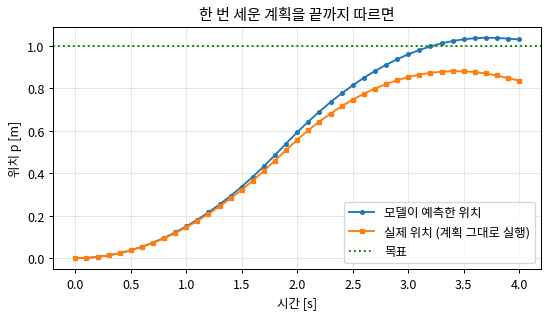

In [3]:
U_plan = plan(x0, np.zeros(40))
X_model = cart_rollout(x0, U_plan)

x = x0.copy(); X_real = [x]
for u in U_plan:                                   # 계획을 끝까지 그대로 실행
    x = real_cart_step(x, u); X_real.append(x)
X_real = np.array(X_real)

t = np.arange(41) * DT
plt.figure(figsize=(7, 3.5))
plt.plot(t, X_model[:, 0], '.-', label='모델이 예측한 위치')
plt.plot(t, X_real[:, 0], 's-', ms=3, label='실제 위치 (계획 그대로 실행)')
plt.axhline(GOAL, color='g', ls=':', label='목표')
plt.xlabel('시간 [s]'); plt.ylabel('위치 p [m]'); plt.legend(); plt.title('한 번 세운 계획을 끝까지 따르면')
plt.show()
print('4초 뒤: 모델 예측 p=%.3f m, 실제 p=%.3f m' % (X_model[-1, 0], X_real[-1, 0]))

**결과 해석:** 모델로는 1 m 근처에 서야 하지만, 실제 카트는 마찰 때문에 덜 가서 약 0.84 m에 선다. 계획은 처음에 한 번 세운 것이고, 실행하는 동안 실제 상태가 계획과 어긋나도 아무도 그것을 보지 않는다.

이렇게 측정을 다시 보지 않고 미리 정한 입력을 그대로 실행하는 방식을 **개루프**(open-loop) 제어라고 한다.

## 2. 아이디어 — 매 순간 다시 계획한다 (receding horizon)

### 아이디어
운전할 때 내비게이션은 출발할 때 경로를 한 번 계산하고 끝내지 않는다. 길을 잘못 들면 **지금 위치에서** 경로를 다시 계산한다. 똑같이 해 보자.

```text
매 스텝(0.1초)마다:
  1. 실제 카트의 지금 상태 x를 측정한다
  2. x에서 시작하는 T스텝짜리 계획을 최적화한다
  3. 계획의 첫 입력 u_0만 실제로 실행한다
  4. 나머지 계획은 버리고(또는 다음 계획의 초기값으로 쓰고) 1로 돌아간다
```

계획하는 구간(horizon)이 시간이 지날수록 앞으로 밀려간다고 해서 **receding horizon**(밀려가는 예측 구간)이라 부른다. 이 방식이 **MPC**(Model Predictive Control, 모델 예측 제어)다. 매 스텝 실제 상태를 다시 보므로 **폐루프**(closed-loop, 피드백) 제어다.

아래 `run_mpc`가 위 의사코드를 그대로 옮긴 것이다(`course.py`에 같은 코드가 있다). 4번의 "다음 계획의 초기값"은 5절에서 설명한다.

In [4]:
def run_mpc(plan, x0, steps, plant_step, U_init, shift=True):
    x, U = np.asarray(x0, float), np.asarray(U_init, float)
    xs, us, plans = [x], [], []
    for _ in range(steps):
        U = plan(x, U)                       # 2. 지금 상태에서 계획
        plans.append(U.copy())
        x = plant_step(x, U[0])              # 3. 첫 입력만 실제로 실행 → 1. 새 상태 측정
        xs.append(x); us.append(U[0])
        U = np.concatenate([U[1:], U[-1:]]) if shift else np.zeros_like(U)   # 4. 다음 초기값
    return np.array(xs), np.array(us), plans

**예측해 보기:** 같은 실제 카트(마찰 있음), horizon T=20(2초)으로 6초 동안 MPC를 돌린다. 모델은 여전히 마찰을 모른다. 이번에는 1 m에 설 수 있을까?

6초 뒤 실제 상태: p=1.000 m, v=0.000 m/s


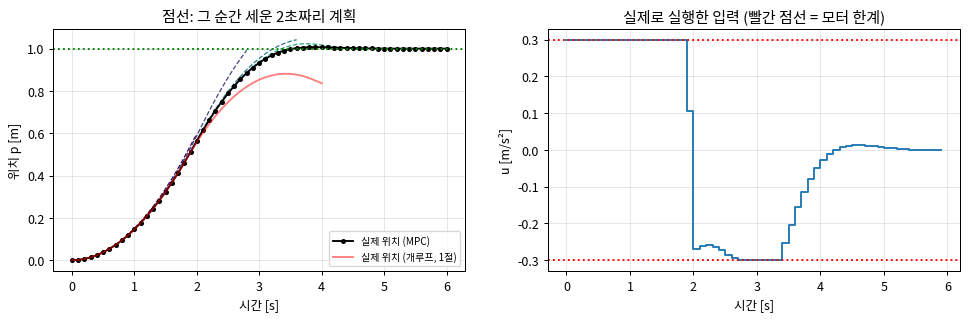

In [5]:
xs, us, plans = run_mpc(plan, x0, 60, real_cart_step, np.zeros(20))
t_run = np.arange(61) * DT

fig, axs = plt.subplots(1, 2, figsize=(13, 3.5))
for k in range(0, 40, 8):                  # 8스텝마다 그 순간의 계획(예측)을 겹쳐 그림
    Xp = cart_rollout(xs[k], plans[k])
    axs[0].plot(t_run[k] + np.arange(21) * DT, Xp[:, 0], '--', lw=1, color=plt.cm.viridis(k / 40))
axs[0].plot(t_run, xs[:, 0], 'k.-', label='실제 위치 (MPC)')
axs[0].plot(t, X_real[:, 0], 'r-', alpha=0.5, label='실제 위치 (개루프, 1절)')
axs[0].axhline(GOAL, color='g', ls=':'); axs[0].set_xlabel('시간 [s]'); axs[0].set_ylabel('위치 p [m]')
axs[0].legend(fontsize=8); axs[0].set_title('점선: 그 순간 세운 2초짜리 계획')
axs[1].step(t_run[:-1], us, where='post'); axs[1].axhline(U_MAX, color='r', ls=':'); axs[1].axhline(-U_MAX, color='r', ls=':')
axs[1].set_xlabel('시간 [s]'); axs[1].set_ylabel('u [m/s²]'); axs[1].set_title('실제로 실행한 입력 (빨간 점선 = 모터 한계)')
plt.show()
print('6초 뒤 실제 상태: p=%.3f m, v=%.3f m/s' % (xs[-1, 0], xs[-1, 1]))

**결과 해석:**
- 모델은 여전히 마찰을 모르는데, MPC는 1 m에 정확히 선다. 마찰 때문에 덜 갔으면 다음 스텝에서 **실제 위치를 보고** 조금 더 가는 계획을 세우기 때문이다.
- 점선(그 순간의 계획)은 매번 조금씩 다르다. 계획은 실행되는 것이 아니라 **첫 입력을 고르기 위한 예측**이다.
- 실행한 입력을 보면 처음에는 모터 한계(+0.3)까지 가속하고, 중간부터 감속한다.

**한 문장으로:** MPC가 모델 오차를 견딜 수 있는 이유를 "측정"과 "다시 계획"이라는 말을 넣어 설명해 보자.

## 3. 외란 — 누가 카트를 밀었다

### 문제
모델 오차뿐 아니라 예상 못 한 일도 생긴다. 3초째에 누군가 카트를 **뒤로 0.3 m** 밀었다고 하자. 이렇게 바깥에서 끼어드는 예상 못 한 변화를 **외란**(disturbance)이라 한다.

**예측해 보기:** 개루프와 MPC는 각각 어떻게 될까?

7초 뒤: MPC p=1.000 m, 개루프 p=0.295 m


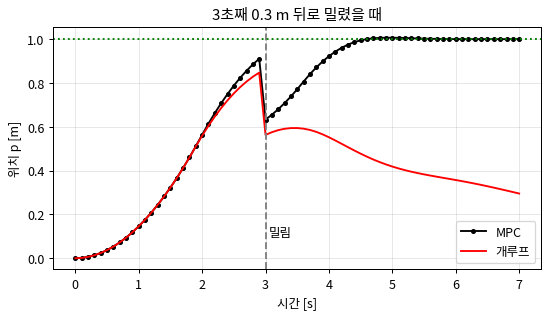

In [6]:
def make_pushed_plant(push_step=30, push=-0.3):
    count = [0]
    def step(x, u):
        count[0] += 1
        x = real_cart_step(x, u)
        if count[0] == push_step:
            x = x + np.array([push, 0.0])          # 위치를 갑자기 0.3 m 뒤로
        return x
    return step

xs_push, _, _ = run_mpc(plan, x0, 70, make_pushed_plant(), np.zeros(20))

pushed = make_pushed_plant(); x = x0.copy(); X_open_push = [x]
U_long = plan(x0, np.zeros(70))                   # 개루프: 7초짜리 계획 하나
for u in U_long:
    x = pushed(x, u); X_open_push.append(x)
X_open_push = np.array(X_open_push)

t70 = np.arange(71) * DT
plt.figure(figsize=(7, 3.5))
plt.plot(t70, xs_push[:, 0], 'k.-', label='MPC')
plt.plot(t70, X_open_push[:, 0], 'r-', label='개루프')
plt.axvline(3.0, color='gray', ls='--'); plt.text(3.05, 0.1, '밀림')
plt.axhline(GOAL, color='g', ls=':'); plt.xlabel('시간 [s]'); plt.ylabel('위치 p [m]'); plt.legend()
plt.title('3초째 0.3 m 뒤로 밀렸을 때'); plt.show()
print('7초 뒤: MPC p=%.3f m, 개루프 p=%.3f m' % (xs_push[-1, 0], X_open_push[-1, 0]))

**결과 해석:** MPC는 밀린 다음 스텝에 바뀐 위치를 보고 다시 가속해 1 m로 돌아온다. 개루프는 밀린 것을 모르고 원래 입력열을 계속 실행하므로, 마찰에 의한 오차 위에 밀린 거리까지 더해져 목표에서 크게 벗어난 채 끝난다.

로봇팔 장면에서 외란의 예가 "갑자기 나타난 손"이다. 계획을 세울 때 없던 장애물이 생기면, MPC는 다음 계획부터 그것을 반영한다(10 노트에서 지도가 갱신되는 과정을 본다).

## 4. horizon 길이 — 얼마나 멀리 볼까

### 문제
horizon $T$는 길수록 좋을까? 짧으면 무엇이 문제일까?

### 아이디어
가속도 한계가 ±0.3 m/s²이라 카트는 급정거할 수 없다. 목표 앞에 서려면 **미리** 감속을 시작해야 한다. horizon이 짧으면 "곧 멈춰야 한다"는 사실이 계획 안에 들어오지 않는다.

**예측해 보기:** T=3(0.3초)과 T=20(2초) 중 어느 쪽이 목표를 더 많이 지나칠까? T=40은 T=20보다 얼마나 더 좋을까?

   T        최대 위치        정착 시간         계획 1번 시간
   3      1.198 m      5.4 s           0.7 ms
   5      1.202 m      5.3 s           1.1 ms
  10      1.094 m      4.7 s           2.9 ms
  20      1.006 m      3.3 s           5.8 ms
  40      1.007 m      3.3 s          25.8 ms


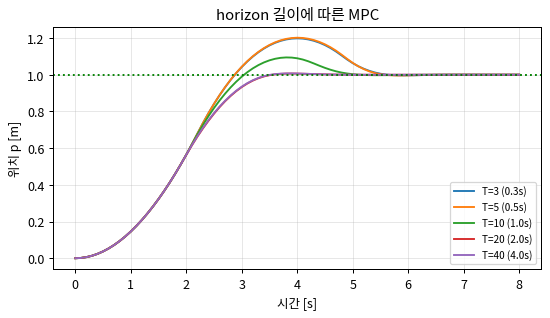

In [7]:
def settle_step(xs, tol=0.02):
    # 그 이후로 계속 목표 ±2 cm 안에 머무는 첫 스텝
    inside = np.abs(xs[:, 0] - GOAL) < tol
    return next((i for i in range(len(inside)) if inside[i:].all()), None)

plt.figure(figsize=(7, 3.5))
print('%4s %12s %12s %16s' % ('T', '최대 위치', '정착 시간', '계획 1번 시간'))
for T in [3, 5, 10, 20, 40]:
    t0 = time.perf_counter()
    xs_T, _, _ = run_mpc(plan, x0, 80, real_cart_step, np.zeros(T))
    per_plan_ms = 1000 * (time.perf_counter() - t0) / 80
    s = settle_step(xs_T)
    print('%4d %10.3f m %10s %13.1f ms' % (T, xs_T[:, 0].max(), '%.1f s' % (s * DT) if s is not None else '-', per_plan_ms))
    plt.plot(np.arange(81) * DT, xs_T[:, 0], label=f'T={T} ({T * DT:.1f}s)')
plt.axhline(GOAL, color='g', ls=':'); plt.xlabel('시간 [s]'); plt.ylabel('위치 p [m]'); plt.legend(fontsize=8)
plt.title('horizon 길이에 따른 MPC'); plt.show()

**결과 해석:**
- T=3, 5: 목표를 20 cm 가까이 지나쳤다가 돌아온다. 정착도 늦다. 0.3~0.5초 앞만 보니, 멈춰야 할 때가 되어서야 감속을 시작하지만 모터 한계 때문에 늦다. 이것이 짧은 horizon의 **근시안**이다.
- T=20: 거의 지나치지 않고 가장 빨리 정착한다.
- T=40: T=20과 결과가 거의 같은데 계획 한 번 시간은 더 길다. 필요한 만큼 멀리 보면 그 이상은 계산만 늘어난다.

horizon은 "충분히 멀리 볼 만큼 길게, 계산이 제때 끝날 만큼 짧게" 정한다. 이 프로젝트의 로봇팔은 약 0.7초 앞을 본다(09 노트).

**직접 해보기:** 0절 셀의 `U_MAX`를 0.3에서 1.0으로 바꾸고 이 셀을 다시 실행해 보자. T=3의 지나침은 어떻게 될까?
<details><summary>실행 결과</summary>

T=3도 거의 지나치지 않는다(최대 약 1.015 m, 정착 약 1.8 s). 브레이크가 세면 목표 직전에 감속해도 늦지 않기 때문이다. 즉 필요한 horizon 길이는 고정된 값이 아니라 **멈추는 데 걸리는 시간**에 달려 있다. 가속 한계가 작고 빠르게 움직이는 시스템일수록 더 멀리 봐야 한다.
</details>

## 5. warm start — 지난 계획을 다음 초기값으로

### 문제
MPC는 매 스텝 최적화를 처음부터 다시 한다. 그런데 0.1초 사이에 상황은 크게 바뀌지 않는다. 방금 세운 계획을 버리고 매번 0에서 다시 시작하는 것은 낭비다.

### 아이디어
방금 계획 $U^* = (u_0^*, u_1^*, \dots, u_{T-1}^*)$에서 $u_0^*$는 이미 실행했다. 남은 $(u_1^*, \dots, u_{T-1}^*)$은 다음 순간의 좋은 출발점이다. 한 칸 앞으로 당기고, 비는 마지막 칸은 마지막 값을 한 번 더 쓴다.

$$
U_{\text{init}} = (u_1^*, u_2^*, \dots, u_{T-1}^*, u_{T-1}^*)
$$

이렇게 이전 해를 다음 최적화의 출발점으로 쓰는 것을 **warm start**라 하고, 0에서 시작하는 것을 cold start라 한다. `run_mpc`의 `shift=True`가 이 동작이다.

**예측해 보기:** warm start를 쓰면 최적화 한 번에 필요한 비용 계산 횟수가 늘까, 줄까?

In [8]:
for shift in [True, False]:
    n_evals.clear()
    run_mpc(plan, x0, 60, real_cart_step, np.zeros(20), shift=shift)
    print('%-11s 최적화 1번당 평균 비용 계산 %.1f회' % ('warm start' if shift else 'cold start', np.mean(n_evals)))

warm start  최적화 1번당 평균 비용 계산 9.1회
cold start  최적화 1번당 평균 비용 계산 15.1회


같은 답을 더 적은 계산으로 찾는다. 계산 시간이 정해져 있을 때는 이 차이가 **결과**의 차이가 된다. 아래는 최적화를 매 스텝 **2번만** 반복할 수 있다고 제한한 경우다.

warm start  6초 뒤 p=1.000 m, 정착 3.3 s
cold start  6초 뒤 p=1.020 m, 정착 6.0 s


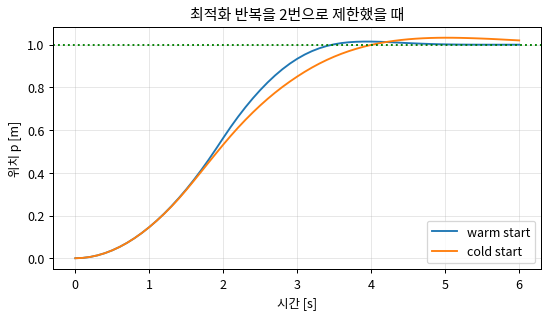

In [9]:
plt.figure(figsize=(7, 3.5))
for shift in [True, False]:
    xs_s, _, _ = run_mpc(lambda x, U: plan(x, U, maxiter=2), x0, 60, real_cart_step, np.zeros(20), shift=shift)
    s = settle_step(xs_s)
    name = 'warm start' if shift else 'cold start'
    print('%-11s 6초 뒤 p=%.3f m, 정착 %s' % (name, xs_s[-1, 0], '%.1f s' % (s * DT) if s is not None else '6초 안에 못 함'))
    plt.plot(np.arange(61) * DT, xs_s[:, 0], label=name)
plt.axhline(GOAL, color='g', ls=':'); plt.xlabel('시간 [s]'); plt.ylabel('위치 p [m]'); plt.legend()
plt.title('최적화 반복을 2번으로 제한했을 때'); plt.show()

**결과 해석:** 반복이 2번뿐이면 cold start는 매번 0에서 조금밖에 못 내려가 엉성한 계획을 실행한다. 6초가 다 되어서야 겨우 ±2 cm 경계(1.020 m)에 들어온다. warm start는 지난 계획에서 이어서 내려가므로, 스텝이 쌓일수록 계획이 좋아져 3초대에 정착한다. 반복 횟수가 고정된 MPC에서 warm start는 사실상 필수다.

## 6. 시간 제약 — 1초에 60번

### 문제
이 프로젝트의 로봇은 1초에 60번(약 16.7 ms마다) 명령을 받는다. 매번 계획을 새로 세우려면 최적화가 16.7 ms 안에 끝나야 한다.

In [10]:
for T in [20, 30]:
    n_evals.clear(); t0 = time.perf_counter()
    run_mpc(plan, x0, 30, real_cart_step, np.zeros(T))
    print('1D 카트, T=%d: 계획 1번 평균 %.1f ms (비용 계산 %.1f회)' % (T, 1000 * (time.perf_counter() - t0) / 30, np.mean(n_evals)))

1D 카트, T=20: 계획 1번 평균 11.1 ms (비용 계산 11.7회)
1D 카트, T=30: 계획 1번 평균 36.3 ms (비용 계산 24.2회)


관절이 하나뿐인 1D 카트도 T=30이면 계획 한 번이 16.7 ms 예산을 넘기기 쉽다(시간은 컴퓨터 상태에 따라 실행마다 조금씩 다르다). 로봇팔은 관절 7개 × 30스텝 = 입력 210개이고, 비용에 충돌 검사까지 들어간다. 경사 기반 최적화는 비용의 기울기가 필요하다. 그런데 03에서 봤듯이 충돌 비용은 멀리서 기울기가 0이고, 반복도 한 걸음씩 차례로 해야 한다.

그래서 다음 노트에서는 다른 길을 택한다. **기울기 없이, 후보 수백 개의 비용만 동시에(GPU에서 병렬로) 계산해서** 계획을 고치는 방법, MPPI다. MPPI도 이 노트의 MPC 루프 안에서 "계획하는 부분"만 바꾼 것이다.

## 핵심 정리

- **개루프**: 계획을 끝까지 그대로 실행. 모델 오차·외란을 보정하지 못한다.
- **MPC**: 매 스텝 실제 상태에서 T스텝 계획을 최적화하고 **첫 입력만** 실행한 뒤 다시 계획한다(receding horizon, 폐루프).
- **horizon**: 너무 짧으면 미리 감속하지 못하는 근시안이 생긴다. 충분히 길면 더 늘려도 계산만 늘어난다.
- **warm start**: 지난 계획을 한 칸 당겨 다음 초기값으로 쓴다. 계산이 줄고, 반복 수가 제한될 때 결과가 좋아진다.
- 로봇은 1초에 60번 계획해야 하므로 빠른 최적화가 필요하다 → 05 MPPI.

## 확인 문제

<details><summary>1. MPC는 매 스텝 계획 전체(T개 입력)를 실행하는가?</summary>

아니다. 첫 입력 하나만 실행하고, 다음 스텝에 새 상태에서 다시 계획한다.
</details>

<details><summary>2. 모델이 마찰을 모르는데도 MPC가 목표에 정확히 서는 이유는?</summary>

매 스텝 실제 상태를 측정해서 그 상태에서 다시 계획하기 때문이다. 마찰로 덜 간 만큼이 다음 계획의 출발점에 반영된다.
</details>

<details><summary>3. horizon을 0.3초로 줄였더니 로봇이 목표를 지나친다. 왜일까?</summary>

0.3초 앞만 봐서는 "곧 멈춰야 한다"는 것이 계획에 들어오지 않아 감속을 늦게 시작한다. 가속도 한계 때문에 늦은 감속으로는 제때 서지 못한다.
</details>

<details><summary>4. warm start에서 마지막 칸을 무엇으로 채우나?</summary>

한 칸 당기면 마지막 칸이 비므로, 계획의 마지막 입력을 한 번 더 쓴다(반복).
</details>

## 실제 프로젝트에서는

`~/franka-depth-mppi/experiment/hand_experiment.py`의 메인 루프가 이 노트의 `run_mpc`와 같은 구조다. Isaac Sim 물리가 "실제 카트" 역할을 하고, 1초에 60번 돈다.

| 이 노트 | hand_experiment.py |
|---|---|
| 지금 상태 측정 | 278–282줄: Isaac Sim에서 관절 위치·속도를 읽음 (`--state-input measured`) |
| `plan(x, U)` | 298줄: `result = mpc.step(current, ...)` (cuRobo MPPI 최적화) |
| 첫 입력 `U[0]` | 301줄: `result.js_action` |
| 실제 카트에 실행 | 317줄: `controller.apply_action(...)`로 관절 목표를 Isaac Sim에 전달 |
| warm start (shift) | cuRobo 내부에서 한 칸 당김 (`control-settings.json`의 `shift_steps: 1`) |

In [11]:
from common import REPO, show_code
show_code(REPO / 'experiment' / 'hand_experiment.py', 298, 301, width=120)

  298|  torch.cuda.synchronize();begin=time.perf_counter();result=mpc.step(current,max_attempts=2);torch.cuda.synchronize();sol ...
  299|  optimizer_start=mpc.solver.optimizers[0].rollout_fn.start_state.clone()
  300|  assert torch.equal(optimizer_start.position,filtered_start.position) and torch.equal(optimizer_start.velocity,filtered_ ...
  301|  solver_command=result.js_action.get_ordered_joint_state(command_names)


## 다음 노트

[05 · 샘플링으로 최적화하기 — MPPI의 핵심](05_mppi_core.ipynb): MPC의 "계획" 부분을 기울기 없이, 후보를 많이 뽑아 비용만 보고 고치는 방식으로 바꾼다.